# E3: LSTM and GRU on CIFAR-10 (replication notebook)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/broistg/deep-learning-CO5085/blob/main/E3/notebooks/E3.ipynb)

Thin notebook: implementation stays in `E3/e3lib/` and `common/`. Set `MODE` in the next cell:

| `MODE` | What it does | Runtime |
|---|---|---|
| `"load"` (default) | Runs the tests, regenerates tables and figures from `E3/results/`, and compares them with saved outputs when available | CPU |
| `"rerun"` | Smoke-tests a model, trains all 12 recurrent runs (four configurations × three seeds) into `E3/results_rerun/`, then regenerates analysis and compares with published results when available | GPU |

E3 uses `hidden_size=128` and `embed_dim=64`; `rerun` writes only to `E3/results_rerun/`. A rerun on another GPU need not match individual accuracies exactly. Protocol: `E3/README.md`.


In [1]:
# 0. Settings
MODE = "load"           # "load" (CPU) or "rerun" (GPU)
FETCH_WEIGHTS = True    # Download E3 weights/logits from Release

REPO_URL = "https://github.com/broistg/deep-learning-CO5085.git"
BRANCH = "main"

assert MODE in {"load", "rerun"}


In [2]:
# 1. Locate or clone the repo, install dependencies on Colab, and expose E3 modules.
import os
import subprocess
import sys
from pathlib import Path

ON_COLAB = "google.colab" in sys.modules
if ON_COLAB:
    repo = Path("/content/deep-learning-CO5085")
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(repo)], check=True)
    else:
        subprocess.run(["git", "-C", str(repo), "pull", "--ff-only"], check=True)
else:
    repo = Path.cwd().resolve()
    while repo != repo.parent and not (repo / "common" / "cifar.py").exists():
        repo = repo.parent
    assert (repo / "common" / "cifar.py").exists(), "Run from inside the repository"

os.chdir(repo)
for module_path in (repo / "E3", repo):
    if str(module_path) not in sys.path:
        sys.path.insert(0, str(module_path))
os.environ["PYTHONPATH"] = os.pathsep.join((str(repo), str(repo / "E3")))
if ON_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/e.txt"], check=True)
from common import notebook_utils as nu
from e3lib.plan import all_cfgs
from e3lib.train import E3_DIR, run
from e3lib import analyze, diagnostics
print("Repository:", repo)


Repository: /content/deep-learning-CO5085


In [3]:
# 2. Show mode, device and run count before doing any training.
import torch
print(f"E3: MODE={MODE} | torch {torch.__version__} | CUDA: {torch.cuda.is_available()}")
print(f"Planned recurrent runs: {len(all_cfgs())}")
if MODE == "rerun":
    assert torch.cuda.is_available(), "Select a GPU runtime for the 12 full CIFAR-10 runs"
    h, n = nu.estimate_hours(E3_DIR / "results")
    if n:
        print(f"Published training estimate: {h:.1f} h for {n} runs on the original GPU, plus evaluation.")
    else:
        print("No published E3 timings yet; recurrent training may take several hours.")


E3: MODE=load | torch 2.14.1+cpu | CUDA: False
Planned recurrent runs: 12


In [4]:
# 3. Tests: models, tokenizers, resume/analysis, and the shared CIFAR split.
for suite in ("E3/tests", "common/tests"):
    subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", suite, "-v"], check=True)


## Load mode


In [5]:
# 4a. (load) Download E3 weights/logits from GitHub Release.
regenerated = E3_DIR / "regenerated"
published = E3_DIR / "results"

published_runs = []
generated_this_run = False
confusion_figure = None
error_grid_figure = None
artifacts_ready = False

if MODE == "load" and FETCH_WEIGHTS:
    nu.fetch_release("e3_artifacts.zip")
    artifacts_ready = True
    print("E3 artifacts ready.")


downloading https://github.com/broistg/deep-learning-CO5085/releases/download/weights-v1/e3_artifacts.zip (9 MB)
e3_artifacts.zip: verified and extracted to /content/deep-learning-CO5085
E3 artifacts ready.


In [6]:
# 4b. (load) Regenerate tables and learning curves.
if MODE == "load":
    published_runs = analyze.load_results(published)

    analyze.main([
        "--results", str(published),
        "--out", str(regenerated)
    ])

    generated_this_run = True

    print(f"Loaded {len(published_runs)}/12 recurrent runs.")


E3: 12/12 LSTM and GRU runs; wrote summary to /content/deep-learning-CO5085/E3/regenerated
Loaded 12/12 recurrent runs.


In [7]:
# 4c. (load) Verify regenerated results.
if MODE == "load":
    nu.compare_outputs(regenerated, published)


OK   tab_e3_summary.tex
(summary.json: 'errors' skipped, the logits were not downloaded)
OK   summary.json
All regenerated tables and numbers equal the committed (= reported) ones.


In [8]:
# 4d. (load) Reproduce E3 confusion matrix.
if MODE == "load" and artifacts_ready:
    diagnostics.main([
        "--results", str(published),
        "--artifacts", str(E3_DIR / "artifacts"),
        "--out", str(regenerated),
        "--run-id", "gru_patch4_s2"
    ])

    confusion_figure = regenerated / "figures" / "confusion_e3.png"

    assert confusion_figure.is_file()
    print("Confusion matrix generated successfully.")


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

hf train split reordered to the torchvision order
E3 diagnostics for gru_patch4_s2: test accuracy 0.6861
Confusion matrix generated successfully.


In [9]:
# 4e. (load) Reproduce 12 most confident errors.
if MODE == "load" and artifacts_ready:
    import json
    import numpy as np
    import matplotlib.pyplot as plt

    from common.cifar import load_cifar, CLASSES

    run_id = "gru_patch4_s2"
    logits, labels = diagnostics.load_predictions(
        E3_DIR / "artifacts" / run_id / "logits_test.pt"
    )

    _, _, images, test_labels = load_cifar()

    assert np.array_equal(
        labels.numpy(), test_labels
    ), "Test labels/order mismatch"

    report = json.loads(
        (regenerated / "diagnostics.json").read_text()
    )
    indices = report["most_confident_error_indices"]

    predictions = logits.argmax(dim=1)
    confidence = logits.softmax(dim=1).max(dim=1).values

    fig, axes = plt.subplots(3, 4, figsize=(12, 9))

    for ax, idx in zip(axes.flat, indices):
        actual = int(labels[idx])
        predicted = int(predictions[idx])

        ax.imshow(images[idx])
        ax.set_title(
            f"True: {CLASSES[actual]}\n"
            f"Pred: {CLASSES[predicted]} "
            f"({confidence[idx].item():.1%})",
            fontsize=9
        )
        ax.axis("off")

    fig.tight_layout()

    error_grid_figure = (
        regenerated / "figures" /
        "error_grid_gru_patch4.png"
    )

    fig.savefig(error_grid_figure, dpi=180, bbox_inches="tight")
    fig.savefig(
        error_grid_figure.with_suffix(".pdf"),
        bbox_inches="tight"
    )
    plt.close(fig)

    print("Error gallery generated successfully.")


Error gallery generated successfully.


## Rerun mode


In [10]:
# 5a. Dry run on synthetic data; it writes no official result or checkpoint.
if MODE == "rerun":
    run(all_cfgs()[0], smoke=True)


In [11]:
# 5b. Train all 12 recurrent runs into a separate directory. Re-running this cell resumes checkpoints and skips verified completed runs.
if MODE == "rerun":
    rerun_dir = E3_DIR / "results_rerun"
    for cfg in all_cfgs():
        run(cfg, out_dir=rerun_dir)


In [12]:
# 5c. Compare with published accuracies when available; regenerate tables and diagnostics from the rerun.
if MODE == "rerun":
    if any(published.glob("*_s*.json")):
        analyze.load_results(published)
        nu.compare_means(rerun_dir, published)
        nu.compare_runs(rerun_dir, published)
    else:
        print("No published E3 recurrent results yet; rerun comparison skipped.")
    analyze.main(["--results", str(rerun_dir), "--out", str(regenerated)])
    generated_this_run = True
    report = diagnostics.main([
        "--results", str(rerun_dir),
        "--artifacts", str(rerun_dir / "artifacts"),
        "--out", str(regenerated),
    ])
    confusion_figure = regenerated / "figures" / "confusion_e3.png"
    stem = report["run_id"].rsplit("_s", 1)[0]
    error_grid_figure = regenerated / "figures" / f"error_grid_{stem}.png"


## Figures and tables


=== E3 Figures ===
confusion_e3.png


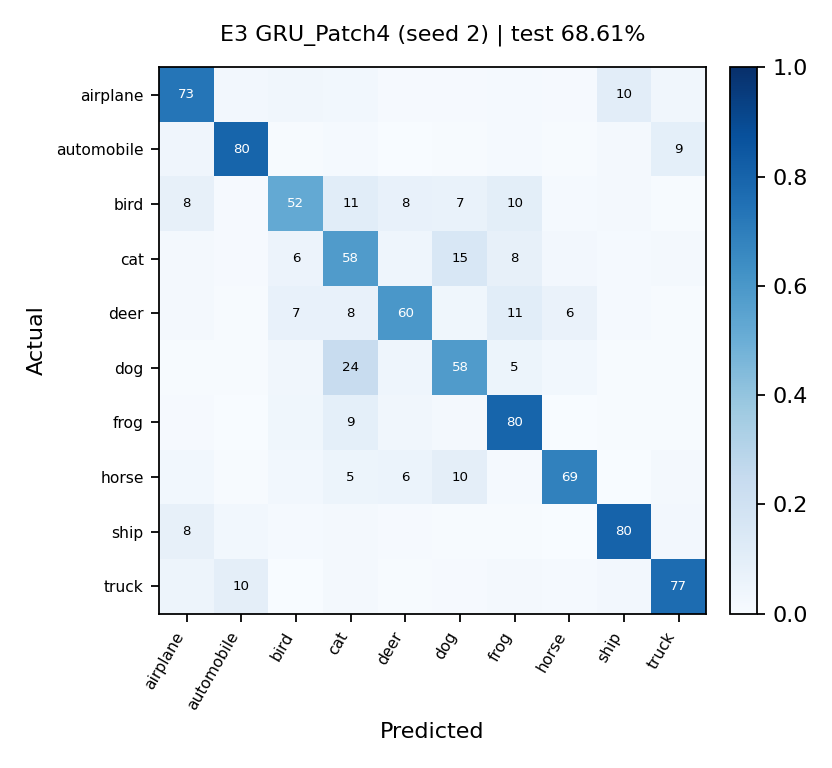

curves_e3.png


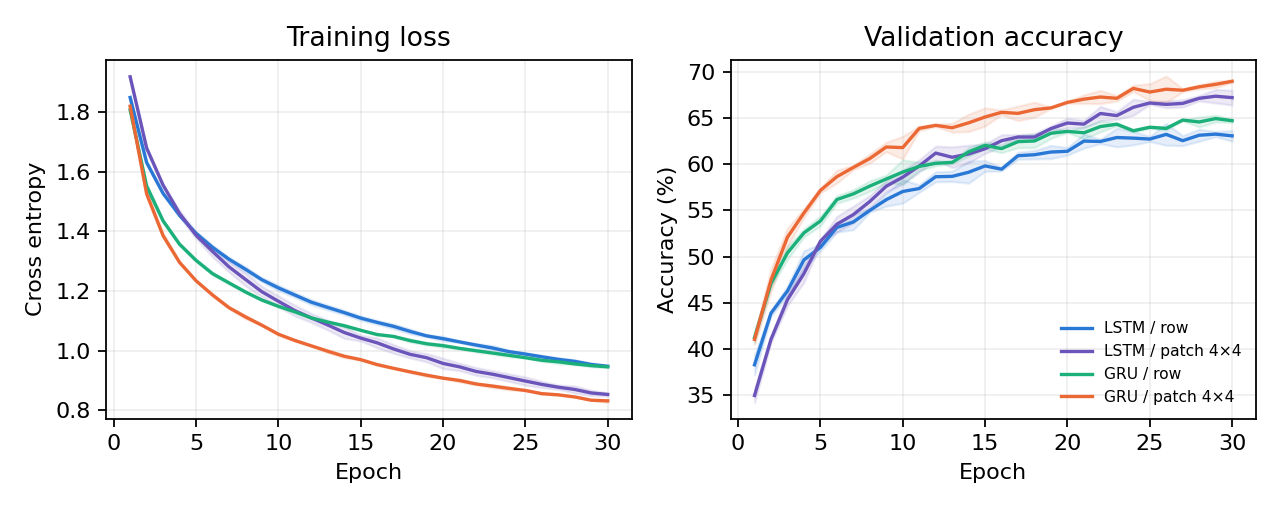

error_grid_gru_patch4.png


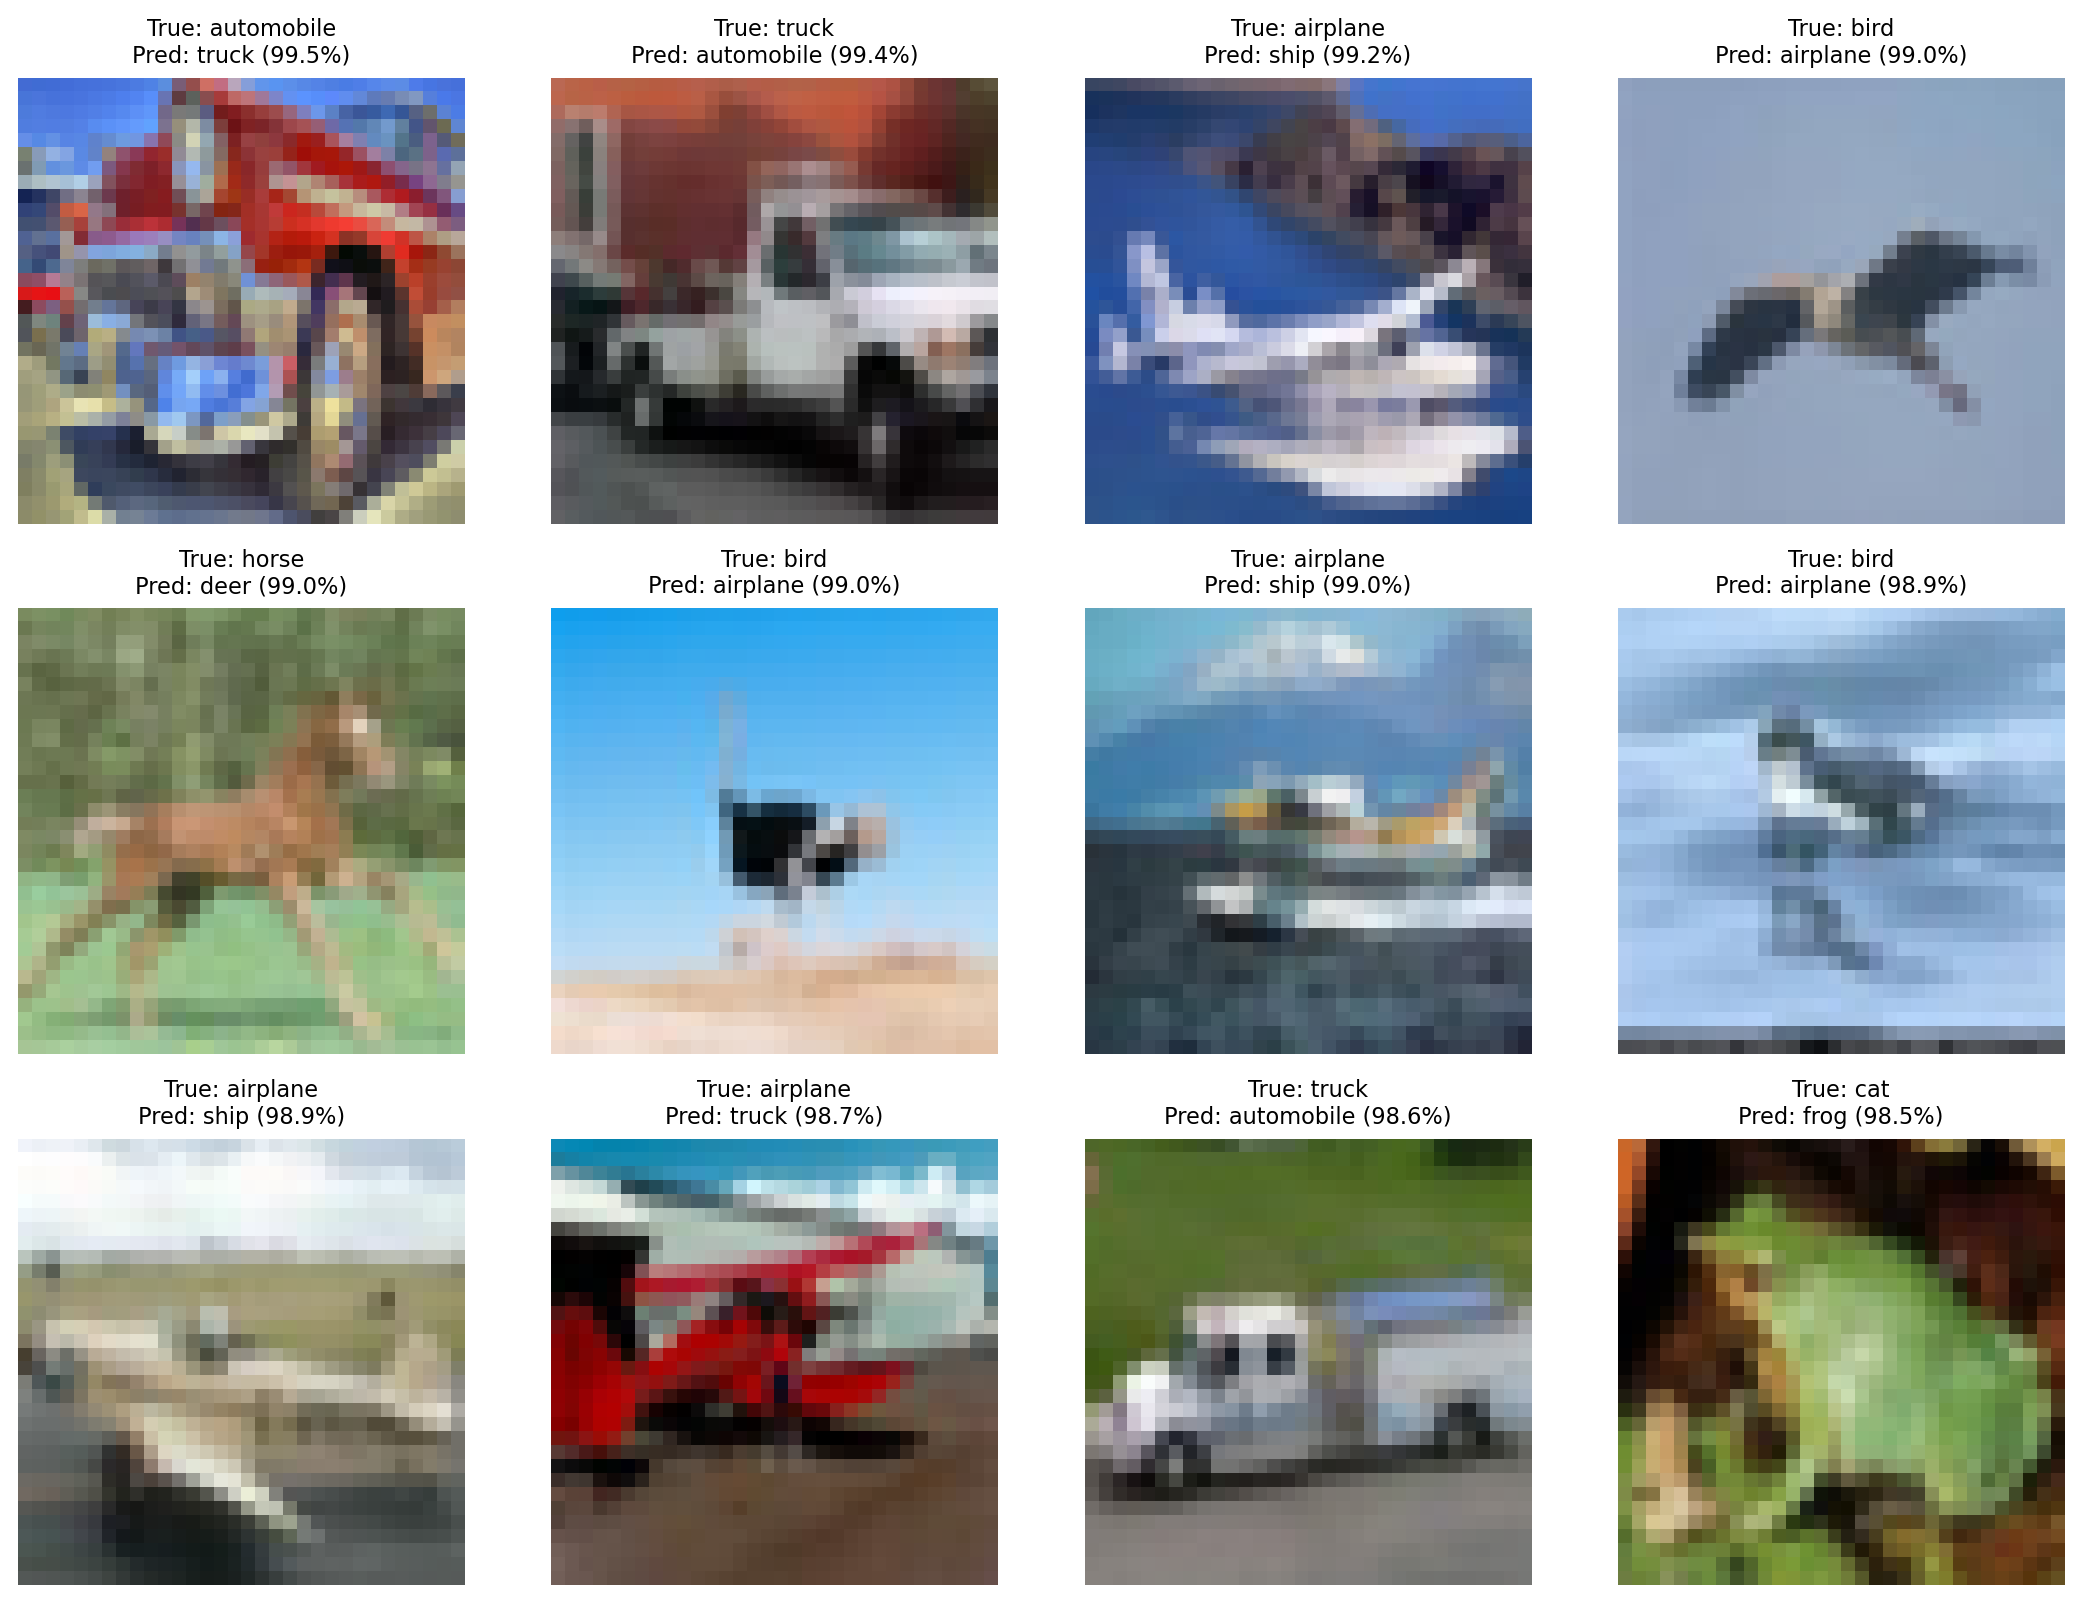


=== E3 Tables ===
--- tab_e3_summary.tex
LSTM / row & 32 & 106\,826 & 63{,}09 $\pm$ 0{,}58 & 63{,}99 $\pm$ 0{,}23 & 8{,}1 & 255{,}7 & 3 \\
LSTM / patch 4×4 & 64 & 103\,754 & 67{,}23 $\pm$ 0{,}80 & 66{,}84 $\pm$ 0{,}82 & 8{,}0 & 313{,}5 & 3 \\
GRU / row & 32 & 81\,994 & 64{,}73 $\pm$ 0{,}18 & 64{,}64 $\pm$ 0{,}42 & 7{,}8 & 245{,}2 & 3 \\
GRU / patch 4×4 & 64 & 78\,922 & 69{,}01 $\pm$ 0{,}14 & 67{,}85 $\pm$ 0{,}76 & 7{,}9 & 296{,}1 & 3 \\



In [13]:
# 6. Show all regenerated figures and tables.
if generated_this_run:
    print("=== E3 Figures ===")
    nu.show_pngs(regenerated / "figures")

    print("\n=== E3 Tables ===")
    for file in sorted(regenerated.glob("tab_*.tex")):
        print("---", file.name)
        print(file.read_text(encoding="utf8"))
else:
    print("No E3 results have been regenerated.")


`E3/results/` and `E3/artifacts/` hold the hidden-128 recurrent runs. `rerun` keeps its results and artifacts under `E3/results_rerun/`; re-executing the notebook resumes them. Once saved tables and summary exist, `load` checks the regenerated numbers against those files. Test-logit diagnostics additionally need local `E3/artifacts/` files.
